Integrantes: María Adelaida Restrepo, Juanita Arenas, Michelle Ruiz, Sofía Berrío y Jerónimo Morales.

**Figura 1**

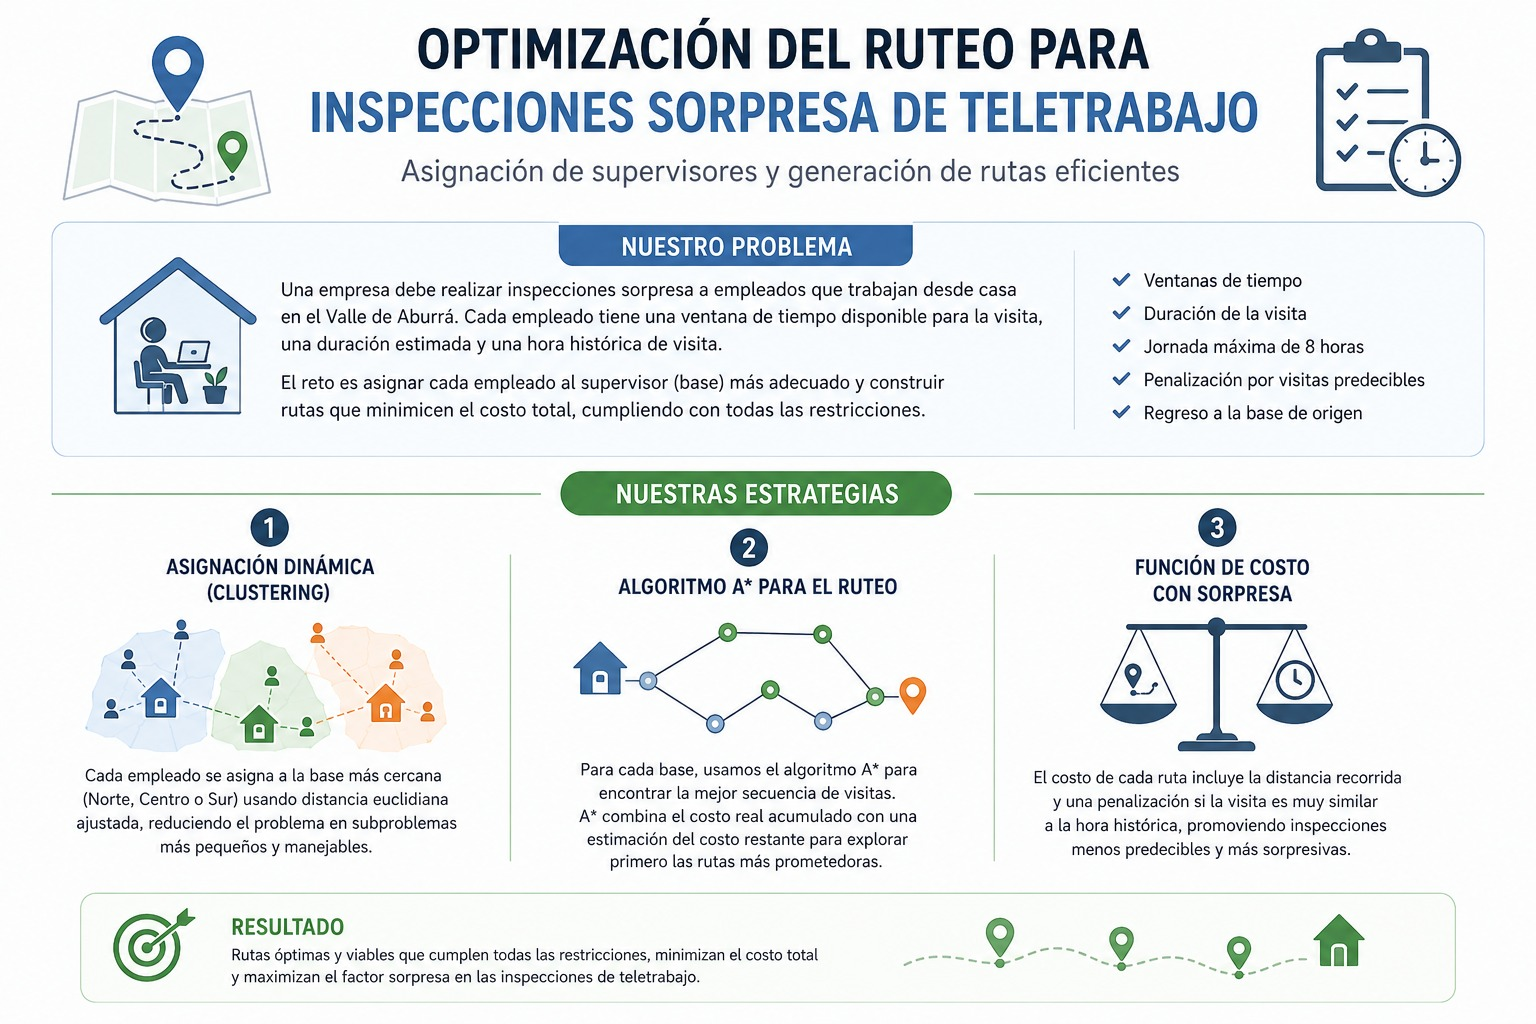

**Figura 2**

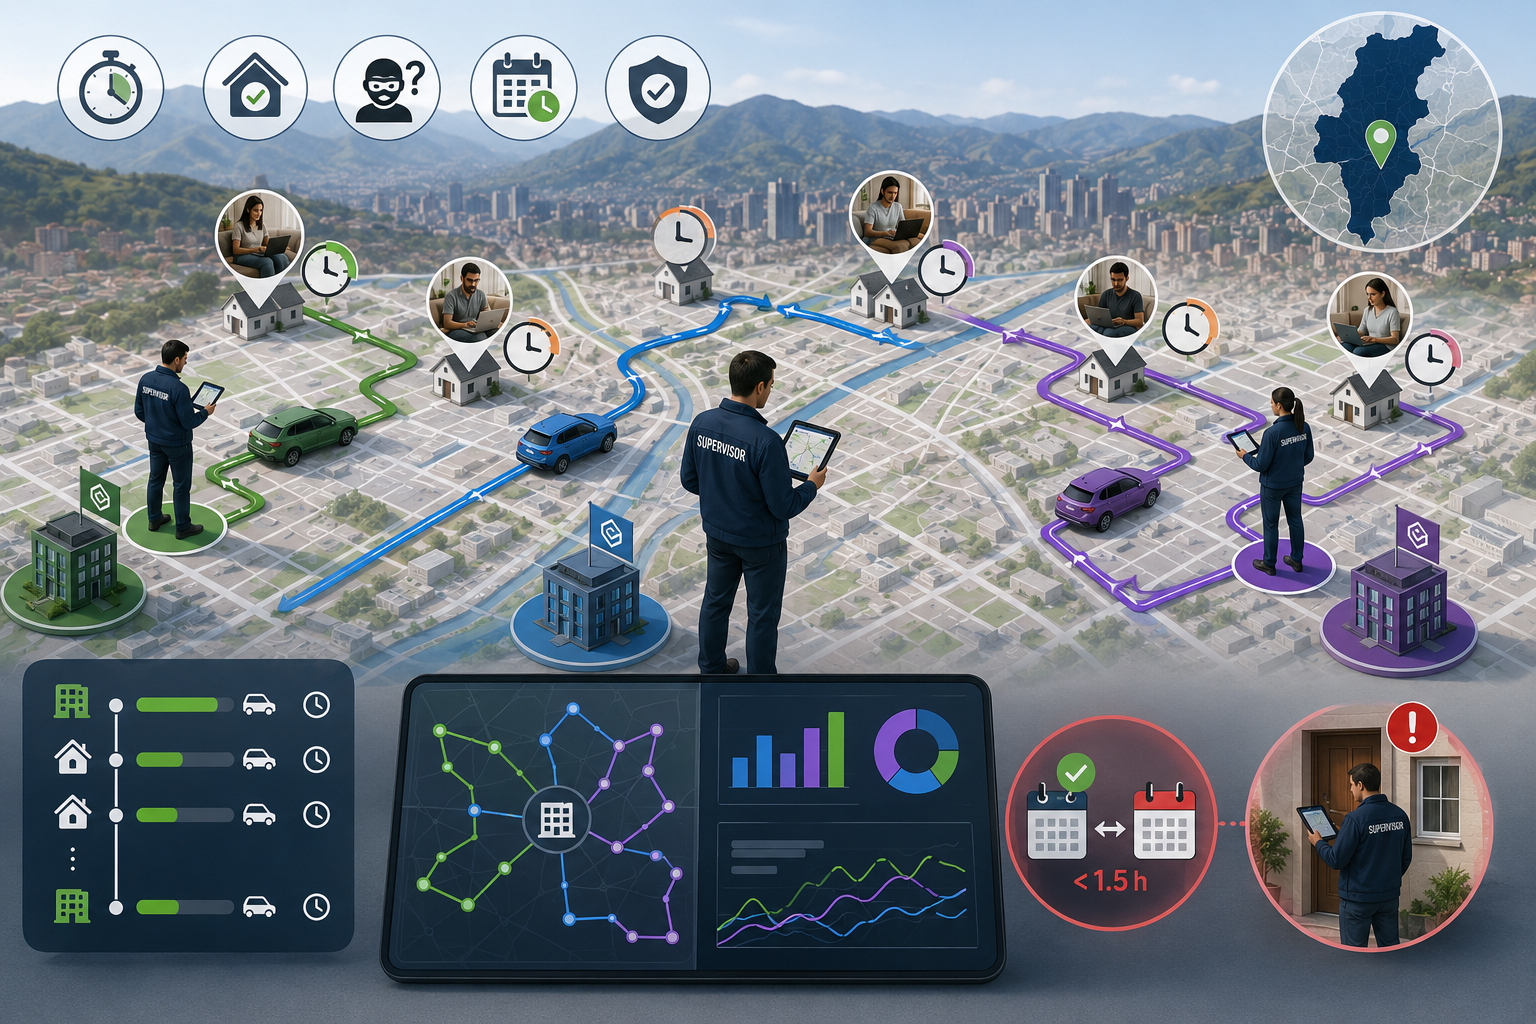

**Figura 3**

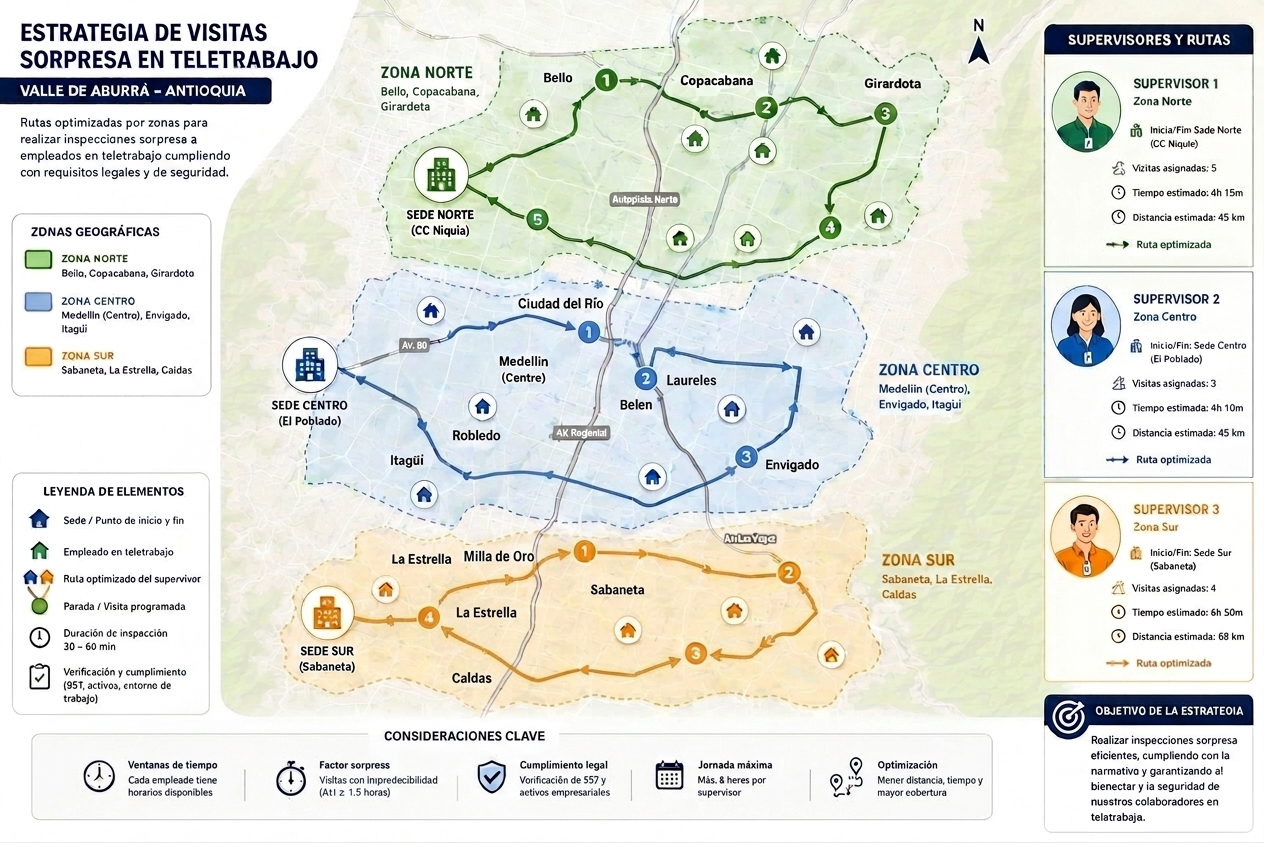

**Figura 4**

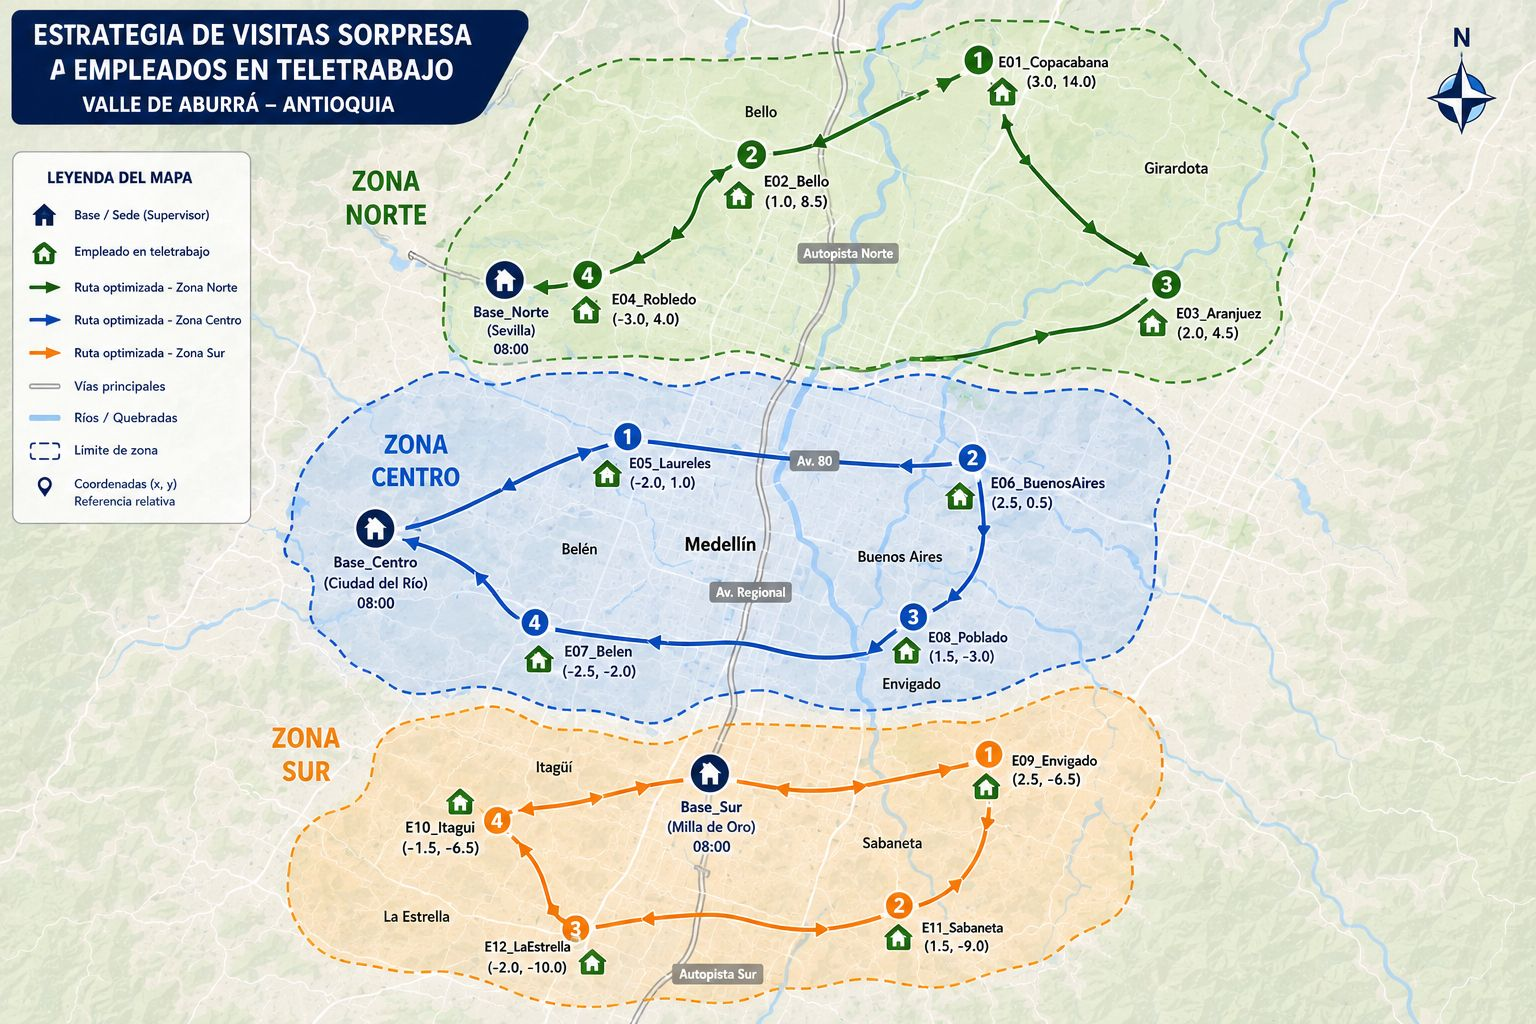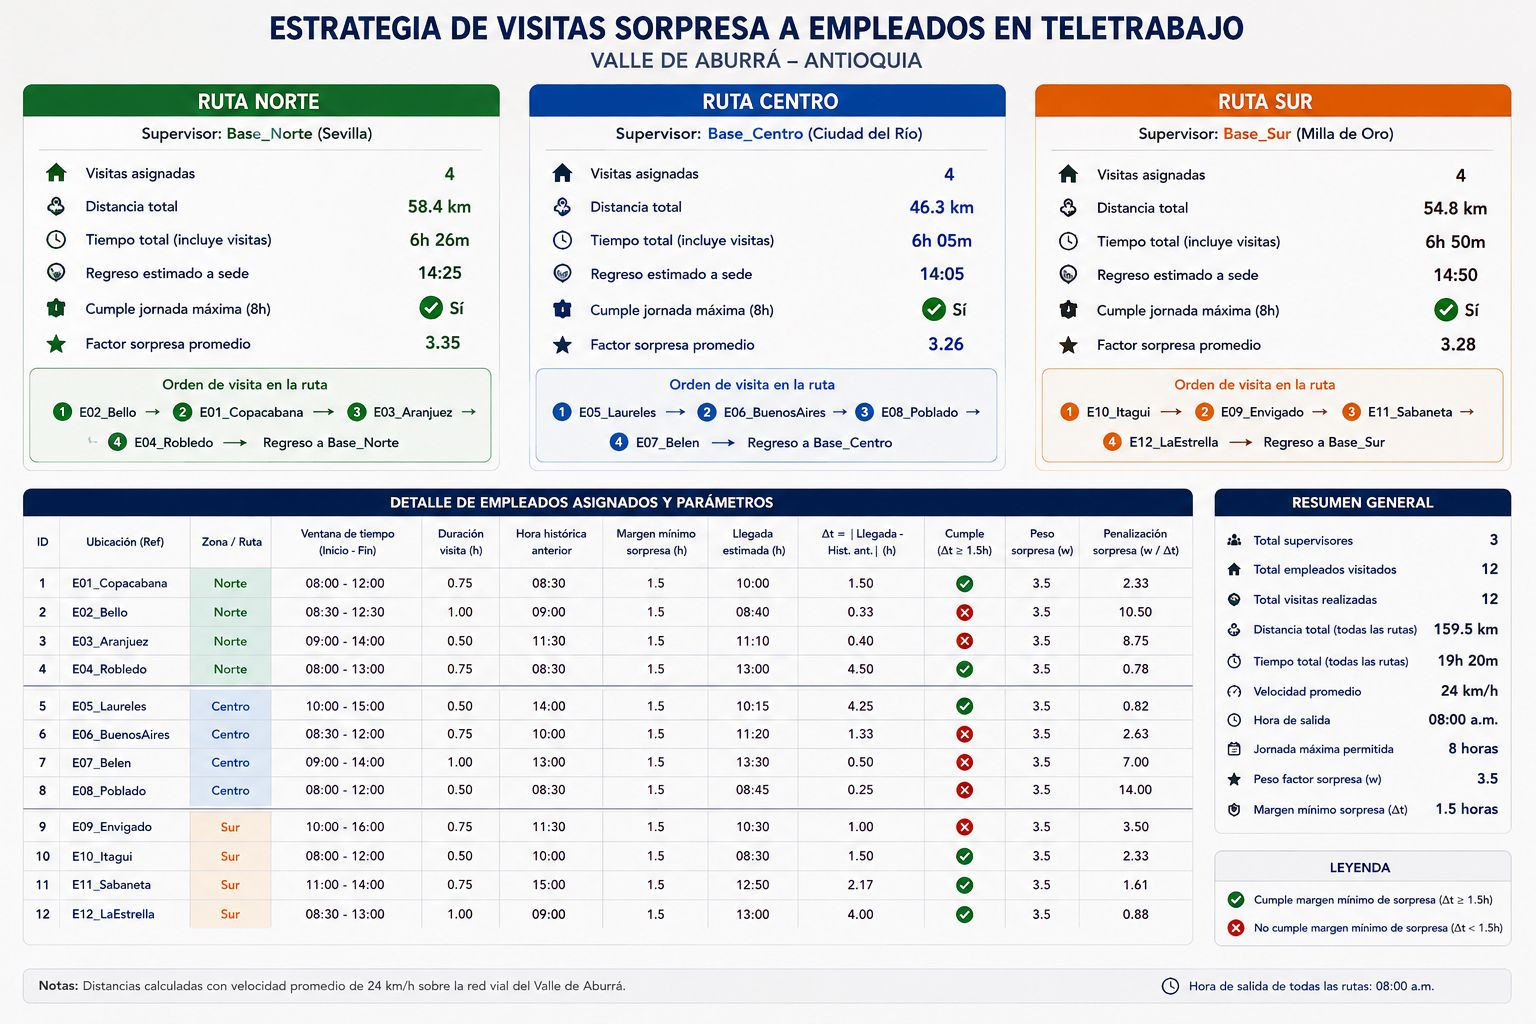

In [ ]:
import heapq
import math

# ==========================================
# 1. DATOS REALISTAS (VALLE DE ABURRÁ)
# ==========================================

# Coordenadas relativas en km respecto a Parques del Río (0,0)
# X: Este(+)/Oeste(-) | Y: Norte(+)/Sur(-)
UBICACIONES = {
    # 3 Bases de los Supervisores
    'Base_Norte':  (0.5, 3.0),   # Ruta N (Sevilla)
    'Base_Centro': (1.0, -1.5),  # Ciudad del Río
    'Base_Sur':    (2.0, -4.5),  # Milla de Oro

    # 12 Teletrabajadores
    'E01_Copacabana': (3.0, 14.0),
    'E02_Bello':      (1.0, 8.5),
    'E03_Aranjuez':   (2.0, 4.5),
    'E04_Robledo':    (-3.0, 4.0),
    'E05_Laureles':   (-2.0, 1.0),
    'E06_BuenosAires':(2.5, 0.5),
    'E07_Belen':      (-2.5, -2.0),
    'E08_Poblado':    (1.5, -3.0),
    'E09_Envigado':   (2.5, -6.5),
    'E10_Itagui':     (-1.5, -6.5),
    'E11_Sabaneta':   (1.5, -9.0),
    'E12_LaEstrella': (-2.0, -10.0)
}

# (Inicio, Fin de ventana), Duración de visita, Hora histórica anterior
EMPLEADOS_INFO = {
    'E01_Copacabana': {'ventana': (8.0, 12.0), 'duracion': 0.75, 'hora_historia': 8.5},
    'E02_Bello':      {'ventana': (8.5, 12.5), 'duracion': 1.00, 'hora_historia': 9.0},
    'E03_Aranjuez':   {'ventana': (9.0, 14.0), 'duracion': 0.50, 'hora_historia': 11.5},
    'E04_Robledo':    {'ventana': (8.0, 13.0), 'duracion': 0.75, 'hora_historia': 8.5},
    'E05_Laureles':   {'ventana': (10.0, 15.0),'duracion': 0.50, 'hora_historia': 14.0},
    'E06_BuenosAires':{'ventana': (8.5, 12.0), 'duracion': 0.75, 'hora_historia': 10.0},
    'E07_Belen':      {'ventana': (9.0, 14.0), 'duracion': 1.00, 'hora_historia': 13.0},
    'E08_Poblado':    {'ventana': (8.0, 12.0), 'duracion': 0.50, 'hora_historia': 8.5},
    'E09_Envigado':   {'ventana': (10.0, 16.0),'duracion': 0.75, 'hora_historia': 11.5},
    'E10_Itagui':     {'ventana': (8.0, 12.0), 'duracion': 0.50, 'hora_historia': 10.0},
    'E11_Sabaneta':   {'ventana': (11.0, 16.0),'duracion': 0.75, 'hora_historia': 15.0},
    'E12_LaEstrella': {'ventana': (8.5, 13.0), 'duracion': 1.00, 'hora_historia': 9.0}
}

VELOCIDAD_KMH = 24.0
PESO_SORPRESA = 3.5
MARGEN_MINIMO = 1.5
HORA_SALIDA = 8.0
MAX_JORNADA = 8.0

# ==========================================
# 2. FUNCIONES DE APOYO:
# ==========================================

def calcular_distancia(nodo1, nodo2): #usa pitágoras para calcular la distancia en línea recta entre dos puntos
    x1, y1 = UBICACIONES[nodo1]
    x2, y2 = UBICACIONES[nodo2]
    distancia_recta = math.sqrt((x2 - x1)**2 + (y2 - y1)**2)
    return distancia_recta * 1.3 #multiplicado por 1.3 para simular que los supervisores van por calles reales y no volando en linea recta

def formatear_hora(hora_decimal): #8.5 = 8:30
    horas = int(hora_decimal)
    minutos = int(round((hora_decimal - horas) * 60))
    if minutos == 60:
        horas += 1
        minutos = 0
    ampm = "AM" if horas < 12 else "PM"
    h_12 = horas if horas <= 12 else horas - 12
    h_12 = 12 if h_12 == 0 else h_12
    return f"{h_12:02d}:{minutos:02d} {ampm}"

# ==========================================
# 3. EL ALGORITMO A* (INTACTO)
# ==========================================

#Evaluar escenarios buscando la ruta con el menos costo total f = g + h
#Algoritmo crea "fotos" de cómo va la ruta --> Cada "foto" recibe una calificación f.
#Calificación mala --> porque se penalizó la sorpresa o hay mucho recorrido --> ruta descartada
class Estado:
    def __init__(self, nodo, pendientes, reloj, g, base_origen, padre=None): #nodo --> donde está el supervisor ahora, pendientes --> a quién falta visitar
        self.nodo = nodo
        self.pendientes = pendientes
        self.reloj = reloj
        self.g = g
        self.padre = padre #la ruta padre: para representarla en un futuro

        if not pendientes:
            self.h = calcular_distancia(nodo, base_origen)
        else:
            self.h = min(calcular_distancia(nodo, p) for p in pendientes)

        self.f = self.g + self.h #h estima  cuando falta por recorrer y self.f = costo acumulado + el costo restante

    def __lt__(self, otro): #priorizar cola de f más bajo
        return self.f < otro.f

def a_estrella_ruteo(base_origen, empleados_asignados):
    estado_inicial = Estado(base_origen, empleados_asignados, HORA_SALIDA, 0.0, base_origen) #0.0 se refiere al costo gastado
    cola_prioridad = [estado_inicial]

    while cola_prioridad: # while --> mientras que haya rutas por explorar, saca la que tenga mejor puntaje f
        actual = heapq.heappop(cola_prioridad)

        if not actual.pendientes: #si ya el supervisor visitó a todos, lo manda de vuelta a la base
            if actual.nodo == base_origen:
                camino = []
                while actual:
                    camino.append(actual.nodo)
                    actual = actual.padre #Si logra hacerlo antes de la 8 horas, devuleve la lista con la ruta ganadora utilizando "padre" para reconstruir pasos hacia atrás
                camino.reverse()
                return camino
            else:
                dist = calcular_distancia(actual.nodo, base_origen)
                t_viaje = dist / VELOCIDAD_KMH
                h_llegada = actual.reloj + t_viaje

                if (h_llegada - HORA_SALIDA) <= MAX_JORNADA:
                    estado_final = Estado(base_origen, [], h_llegada, actual.g + dist, base_origen, actual)
                    heapq.heappush(cola_prioridad, estado_final)
            continue

        for siguiente in actual.pendientes: #simula qué pasaría si visita a cada uno de los empleados pendientes
            dist = calcular_distancia(actual.nodo, siguiente)
            t_viaje = dist / VELOCIDAD_KMH
            h_llegada = actual.reloj + t_viaje

            info = EMPLEADOS_INFO[siguiente]

            if h_llegada > info['ventana'][1]:
                continue #continue es para abortar idea, continuar con la siguiente simulación

            h_inicio = max(h_llegada, info['ventana'][0]) #max para el tiempo de espera que podría tener que tener el supervisor
            h_fin = h_inicio + info['duracion']

            if (h_fin - HORA_SALIDA) > MAX_JORNADA:
                continue

            penalidad = 0 #penalidad evaluando el factor sorpresa. Multa es proporcional --> entre más predecible el horario, mayor será la multa
            dif_horas = abs(h_inicio - info['hora_historia'])
            if dif_horas < MARGEN_MINIMO:
                penalidad = (MARGEN_MINIMO - dif_horas) * PESO_SORPRESA

            #si la simulación sobrevivió a todos los filtros anteriores, el sistema lo oficializa como una opción viable
            nuevo_g = actual.g + dist + penalidad #nuevo g = nuevo costo

            nuevos_pendientes = [p for p in actual.pendientes if p != siguiente]

            hijo = Estado(siguiente, nuevos_pendientes, h_fin, nuevo_g, base_origen, actual) #hijo = nueva "foto"
            heapq.heappush(cola_prioridad, hijo)

    return None

# ==========================================
# 4. EJECUCIÓN (CON 3 ZONAS DINÁMICAS)
# ==========================================

if __name__ == "__main__":
    print("=== SISTEMA DE RUTEO IA - VALLE DE ABURRÁ (12 EMPLEADOS / 3 ZONAS) ===\n")

    # 1. CLUSTERING DINÁMICO
    # Creamos las 3 listas vacías para las 3 bases
    bases_operativas = ['Base_Norte', 'Base_Centro', 'Base_Sur']
    zonas = {base: [] for base in bases_operativas}

    # Asignamos cada empleado a su base más cercana
    for emp in EMPLEADOS_INFO.keys():
        base_mas_cercana = min(bases_operativas, key=lambda b: calcular_distancia(emp, b))
        zonas[base_mas_cercana].append(emp)

    # 2. RESOLVER RUTAS
    for base, empleados in zonas.items(): #Pasa base por base y le envía sus respectivos empleados asignados al algoritmo A* para que calcule la ruta perfecta
        print(f"📍 {base.replace('_', ' ').upper()} (Supervisa a: {len(empleados)} empleados)")

        # A* hace su magia para la zona
        ruta = a_estrella_ruteo(base, empleados)

        if ruta: #simulación de lo que sería el recorrido del supervisor
            print(f"   Ruta: {' -> '.join(ruta)}")
            reloj = HORA_SALIDA

            for i in range(1, len(ruta)):
                origen, destino = ruta[i-1], ruta[i]
                dist = calcular_distancia(origen, destino)
                reloj += (dist / VELOCIDAD_KMH)

                if destino == base:
                    print(f"   [{formatear_hora(reloj)}] Retorno a {base}")
                else:
                    info = EMPLEADOS_INFO[destino]
                    h_inicio = max(reloj, info['ventana'][0])

                    if h_inicio > reloj: #para tiempos muertos --> el sistema detecta que hay espera
                        espera = int((h_inicio - reloj) * 60)
                        print(f"   [!] Espera de {espera} min en {destino} (Ventana abre a las {formatear_hora(info['ventana'][0])})")

                    reloj = h_inicio + info['duracion']

                    dif = abs(h_inicio - info['hora_historia'])
                    sorpresa = "✓ Sorpresa lograda" if dif >= MARGEN_MINIMO else "✕ Penalizado (Predecible)"

                    print(f"   [{formatear_hora(h_inicio)}] Visita a {destino} | Historial: {formatear_hora(info['hora_historia'])} ({sorpresa})")
        else:
            print("   ✕ Ruta no viable (Tiempo insuficiente).")
        print("-" * 75)

=== SISTEMA DE RUTEO IA - VALLE DE ABURRÁ (12 EMPLEADOS / 3 ZONAS) ===

📍 BASE NORTE (Supervisa a: 5 empleados)
   Ruta: Base_Norte -> E03_Aranjuez -> E01_Copacabana -> E02_Bello -> E04_Robledo -> E05_Laureles -> Base_Norte
   [!] Espera de 53 min en E03_Aranjuez (Ventana abre a las 09:00 AM)
   [09:00 AM] Visita a E03_Aranjuez | Historial: 11:30 AM (✓ Sorpresa lograda)
   [10:01 AM] Visita a E01_Copacabana | Historial: 08:30 AM (✓ Sorpresa lograda)
   [11:05 AM] Visita a E02_Bello | Historial: 09:00 AM (✓ Sorpresa lograda)
   [12:25 PM] Visita a E04_Robledo | Historial: 08:30 AM (✓ Sorpresa lograda)
   [01:20 PM] Visita a E05_Laureles | Historial: 02:00 PM (✕ Penalizado (Predecible))
   [02:00 PM] Retorno a Base_Norte
---------------------------------------------------------------------------
📍 BASE CENTRO (Supervisa a: 3 empleados)
   Ruta: Base_Centro -> E06_BuenosAires -> E07_Belen -> E08_Poblado -> Base_Centro
   [!] Espera de 21 min en E06_BuenosAires (Ventana abre a las 08:30 AM

**Fuentes**

Figura 1: https://chatgpt.com/c/6a7e6715-2d8c-83e9-88c3-caf70c8226c2

Figura 2: https://chatgpt.com/share/6a7f37c2-0774-83e9-87ce-1189a2b1f2fd

Figura 3:https://share.gemini.google/R2sn97y5t9ey

Figura 4:https://chatgpt.com/c/6a6cc881-4810-83e9-9ec3-52c2c2cd3f7e

Figura 5: https://chatgpt.com/c/6a6cc881-4810-83e9-9ec3-52c2c2cd3f7e

Código: https://share.gemini.google/QEZ7M4NydscX

